# CÀI ĐẶT THUẬT TOÁN

In [1]:
import numpy as np

class SoftmaxRegressionNumpy:
    def __init__(self, lr=0.05, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.W = None
        self.b = None
        self.loss_history = []

    def _softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _one_hot(self, y, num_classes):
        return np.eye(num_classes)[y]

    def fit(self, X, y, num_classes=3):
        n_samples, n_features = X.shape
        self.W = np.zeros((n_features, num_classes))
        self.b = np.zeros(num_classes)
        self.loss_history = []
        Y_onehot = self._one_hot(y, num_classes)

        for _ in range(self.epochs):
            logits = np.dot(X, self.W) + self.b
            probs = self._softmax(logits)

            eps = 1e-15
            loss = -np.mean(np.sum(Y_onehot * np.log(np.clip(probs, eps, 1.0)), axis=1))
            self.loss_history.append(loss)

            dW = (1.0 / n_samples) * np.dot(X.T, (probs - Y_onehot))
            db = (1.0 / n_samples) * np.sum(probs - Y_onehot, axis=0)

            self.W -= self.lr * dW
            self.b -= self.lr * db

    def predict(self, X):
        probs = self._softmax(np.dot(X, self.W) + self.b)
        return np.argmax(probs, axis=1)

def evaluate_multiclass(y_true, y_pred, num_classes=3):
    precisions, recalls, f1s = [], [], []
    for c in range(num_classes):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        precisions.append(p)
        recalls.append(r)
        f1s.append(f)

    acc = np.mean(y_true == y_pred)
    macro_p = np.mean(precisions)
    macro_r = np.mean(recalls)
    macro_f = np.mean(f1s)
    return acc, macro_p, macro_r, macro_f, precisions, recalls, f1s

# HUẤN LUYỆN MÔ HÌNH 

In [3]:
import numpy as np
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5_ratio'] = df['Close'] / df['Close'].rolling(5).mean() - 1
df['MA20_ratio'] = df['Close'] / df['Close'].rolling(20).mean() - 1
df['Volume_change'] = df['Volume'].pct_change()

df['Next_Return'] = df['Return'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

conditions = [
    df['Next_Return'] < -0.005,
    (df['Next_Return'] >= -0.005) & (df['Next_Return'] <= 0.005),
    df['Next_Return'] > 0.005
]
df['Target_Multi'] = np.select(conditions, [0, 1, 2]).astype(int)

feature_cols = ['Return', 'Vol_5d', 'MA5_ratio', 'MA20_ratio', 'Volume_change']
X = df[feature_cols].values
X = (X - X.mean(axis=0)) / X.std(axis=0)

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_mul_train, y_mul_test = df['Target_Multi'].values[:split_idx], df['Target_Multi'].values[split_idx:]

model_mul = SoftmaxRegressionNumpy(lr=0.05, epochs=1000)
model_mul.fit(X_train, y_mul_train, num_classes=3)

y_pred_mul = model_mul.predict(X_test)
acc, mp, mr, mf, p_class, r_class, f_class = evaluate_multiclass(y_mul_test, y_pred_mul, num_classes=3)

print("=" * 60)
print(f"KẾT QUẢ ĐÁNH GIÁ (Bài 2 - Hồi quy Softmax):")
print(f"- Accuracy (Độ chính xác) : {acc:.4f}")
print(f"- Macro Precision         : {mp:.4f}")
print(f"- Macro Recall            : {mr:.4f}")
print(f"- Macro F1-Score          : {mf:.4f}")
print("-" * 60)
class_names = ["Giảm mạnh (0)", "Đi ngang (1)", "Tăng mạnh (2)"]
for i, name in enumerate(class_names):
    print(f"  + Lớp {name:15s} | Precision: {p_class[i]:.4f} | Recall: {r_class[i]:.4f} | F1: {f_class[i]:.4f}")
print("=" * 60)

KẾT QUẢ ĐÁNH GIÁ (Bài 2 - Hồi quy Softmax):
- Accuracy (Độ chính xác) : 0.5234
- Macro Precision         : 0.4225
- Macro Recall            : 0.3713
- Macro F1-Score          : 0.3209
------------------------------------------------------------
  + Lớp Giảm mạnh (0)   | Precision: 0.3116 | Recall: 0.0754 | F1: 0.1214
  + Lớp Đi ngang (1)    | Precision: 0.5435 | Recall: 0.9461 | F1: 0.6904
  + Lớp Tăng mạnh (2)   | Precision: 0.4125 | Recall: 0.0923 | F1: 0.1508


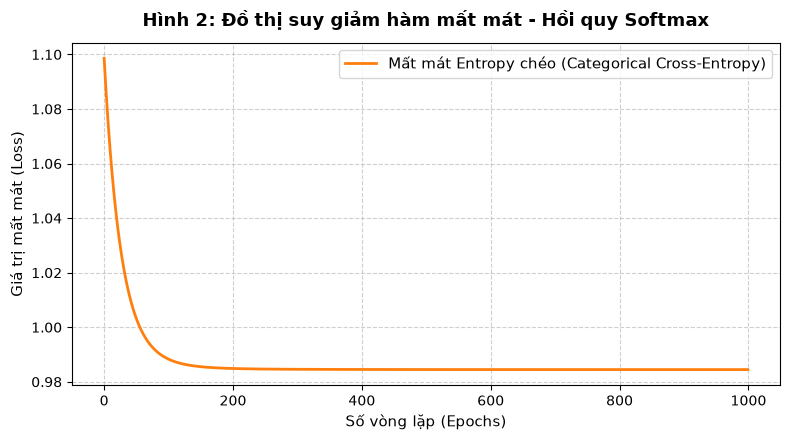

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5), dpi=100)
plt.plot(model_mul.loss_history, color='#ff7f0e', linewidth=2, label='Mất mát Entropy chéo (Categorical Cross-Entropy)')

plt.title("Hình 2: Đồ thị suy giảm hàm mất mát - Hồi quy Softmax", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()
